Problem from paper: A physics-informed deep learning framework for inversion and surrogate modeling in solid mechanics

We can use the Cox de Boor algorithm for more efficient bspline computation.

In [8]:
import numpy as np
from scipy.sparse import kron, diags, identity, csr_matrix
from scipy.sparse.linalg import gmres, LinearOperator, spilu

# ----------------------------
# 1. Build 2D Poisson matrix (finite difference approximation)
# ----------------------------
nx = ny = 50  # grid points in x and y
N = nx * ny

# 1D Laplacian
e = np.ones(nx)
T = diags([ -e, 2*e, -e ], [-1, 0, 1], shape=(nx, nx))

# 2D Laplacian = kron(I, T) + kron(T, I)
I = identity(nx)
A = kron(I, T) + kron(T, I)
A = csr_matrix(A)  # sparse CSR format

# Right-hand side
b = np.ones(N)

# ----------------------------
# 2. Preconditioner: ILU
# ----------------------------
ilu = spilu(A)
M = LinearOperator(A.shape, matvec=ilu.solve)

# ----------------------------
# 3. Iteration counter
# ----------------------------
iteration_counter = []

def callback(rk):
    iteration_counter.append(rk)

# ----------------------------
# 4. Solve with GMRES
# ----------------------------
x, info = gmres(A, b, M=M, restart=50, tol=1e-8, maxiter=1000, callback=callback)

# ----------------------------
# 5. Results
# ----------------------------
if info == 0:
    print("✅ GMRES converged successfully.")
elif info > 0:
    print(f"⚠️ GMRES did not converge. Iterations done: {info}")
else:
    print("❌ GMRES failed.")

print(f"Total iterations performed: {len(iteration_counter)}")
print(f"Final residual norm: {np.linalg.norm(b - A @ x):.2e}")

# ----------------------------
# 6. Optional: print residual per iteration
# ----------------------------
for i, r in enumerate(iteration_counter, start=1):
    print(f"Iteration {i}: residual = {r:.2e}")


✅ GMRES converged successfully.
Total iterations performed: 35
Final residual norm: 2.25e-07
Iteration 1: residual = 4.49e+00
Iteration 2: residual = 3.51e+00
Iteration 3: residual = 2.26e+00
Iteration 4: residual = 1.74e+00
Iteration 5: residual = 9.07e-01
Iteration 6: residual = 6.74e-01
Iteration 7: residual = 4.70e-01
Iteration 8: residual = 3.37e-01
Iteration 9: residual = 1.02e-01
Iteration 10: residual = 4.11e-02
Iteration 11: residual = 2.24e-02
Iteration 12: residual = 1.17e-02
Iteration 13: residual = 7.48e-03
Iteration 14: residual = 2.97e-03
Iteration 15: residual = 1.50e-03
Iteration 16: residual = 4.52e-04
Iteration 17: residual = 1.77e-04
Iteration 18: residual = 6.15e-05
Iteration 19: residual = 3.59e-05
Iteration 20: residual = 1.83e-05
Iteration 21: residual = 7.16e-06
Iteration 22: residual = 3.91e-06
Iteration 23: residual = 2.64e-06
Iteration 24: residual = 1.30e-06
Iteration 25: residual = 5.60e-07
Iteration 26: residual = 1.98e-07
Iteration 27: residual = 9.94e-0

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Define u_x and u_y based on two different Bspline networks including the zero Dirichlet BC

########## u_x ##########
class bsplines_x:

    def __init__(self, n_basis, degree, device):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.rand(n_basis, n_basis, device=device, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x,device):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0], device=device)

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(self.n_basis):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y
    # send every attribute to device
    def to(self, device):
        for attr, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, attr, value.to(device))
    


In [3]:

########## u_y ##########
class bsplines_y:

    def __init__(self, n_basis, degree, device):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        

        # 2D trainable coefficients
        self.coeffs = torch.rand(n_basis, n_basis, device=device, requires_grad=True)

        # 2D input
    

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x, device):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0], device=device)

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(1,(self.n_basis-1)):
            for j in range(1,self.n_basis):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y
    # send every attribute to device
    def to(self, device):
        for attr, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, attr, value.to(device))


In [4]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
torch.manual_seed(42)

model_y = bsplines_y(20,3, device)
model_x = bsplines_x(20,3, device)

model_y.to(device)
model_x.to(device)


In [7]:
# Lame parameters
l=1
mu=0.5
Q=4

In [8]:
def generate_points(n_interior, n_boundary):
    # Interior points
    torch.manual_seed(42)
    xy_in = torch.rand(n_interior, 2)
    # Boundary points on [0,1]^2
    lin = torch.linspace(0, 1, n_boundary).unsqueeze(1)
    zero = torch.zeros_like(lin)
    one = torch.ones_like(lin)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b_u = b2
    xy_b_v = torch.cat([b3, b4], dim=0)
    return xy_in, xy_b_u, xy_b_v 

In [9]:
X, X_b_u, X_b_v = generate_points(5000, 5000)

X = X.to(device)
X_b_v = X_b_v.to(device)
X_b_u = X_b_u.to(device)
X.requires_grad_(True)
X_b_v.requires_grad_(True)
X_b_u.requires_grad_(True)

tensor([[0.0000e+00, 1.0000e+00],
        [2.0004e-04, 1.0000e+00],
        [4.0008e-04, 1.0000e+00],
        ...,
        [9.9960e-01, 1.0000e+00],
        [9.9980e-01, 1.0000e+00],
        [1.0000e+00, 1.0000e+00]], device='cuda:0', requires_grad=True)

In [10]:
X_b_u.shape

torch.Size([5000, 2])

In [16]:
def boundary_loss_v(model_x, model_y, X_b_v, device):
    # X_b_v.requires_grad_(True)
    # Displacements u_x, u_y
    u_x = model_x.forward(X_b_v, device)
    u_y = model_y.forward(X_b_v, device)

    # Gradients of u_x
    grads = torch.autograd.grad(u_x, X_b_v, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_x_x = grads[:, 0]

    # Gradients of u_y
    grads = torch.autograd.grad(u_y, X_b_v, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    u_y_y = grads[:, 1]

    # Stress components
    sigma_xx = (2*mu+l)*u_x_x + l*u_y_y

    
    return torch.mean(sigma_xx**2)

def boundary_loss_u(model_x, model_y, X_b_u, device):
    # Displacements u_x, u_y
    u_x = model_x.forward(X_b_u, device)
    u_y = model_y.forward(X_b_u, device)

    # Gradients of u_x
    grads = torch.autograd.grad(u_x, X_b_u, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_x_x = grads[:, 0]

    # Gradients of u_y
    grads = torch.autograd.grad(u_y, X_b_u, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    u_y_y = grads[:, 1]

    # Stress components
    sigma_yy = (2*mu+l)*u_y_y + l*u_x_x

    # Apply the upper sinusodial BC
    res = sigma_yy-(l+2*mu)*Q*torch.sin(torch.pi*X_b_u[:,0])
    
    return torch.mean(res**2)

# Interior forces
def f_x(X):
    return l*(4*np.pi*2*torch.cos(2*np.pi*X[:,0])*torch.sin(np.pi*X[:,1])-np.pi*torch.cos(np.pi*X[:,0])*Q*X[:,1]**3)+mu*(9*np.pi**2*torch.cos(2*np.pi*X[:,0])*torch.sin(np.pi*X[:,1])-np.pi*torch.cos(np.pi*X[:,0])*Q*X[:,1]**3)
def f_y(X):
    return l*(-3*torch.sin(np.pi*X[:,0])*Q*X[:,1]**2+2*np.pi**2*torch.sin(2*np.pi*X[:,0])*torch.cos(np.pi*X[:,1]))+mu*(-6*torch.sin(np.pi*X[:,0])*Q*X[:,1]**2+2*np.pi**2*torch.sin(2*np.pi*X[:,0])*torch.cos(np.pi*X[:,1])+np.pi**2*torch.sin(np.pi*X[:,0])*Q*X[:,1]**4/4)




In [22]:
learning_rate=1e-4
optimizer = torch.optim.Adam([model_x.coeffs, model_y.coeffs], lr=learning_rate)

In [13]:
loss_vec = []

In [37]:

epochs = 10000

for epoch in range(epochs):
    
    optimizer.zero_grad()
    # Displacements u_x, u_y
    u_x = model_s_x.forward(X, device)
    u_y = model_s_y.forward(X, device)

    # Gradients of u_x
    grads = torch.autograd.grad(u_x, X, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_x_x = grads[:, 0]
    u_x_y = grads[:, 1]

    # Gradients of u_y
    grads = torch.autograd.grad(u_y, X, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    u_y_x = grads[:, 0]
    u_y_y = grads[:, 1]

    # Stress components
    sigma_xx = (2*mu+l)*u_x_x + l*u_y_y
    sigma_yy = (2*mu+l)*u_y_y + l*u_x_x
    sigma_xy = mu*(u_x_y + u_y_x)

    # Stress gradients
    sigma_xx_x = torch.autograd.grad(sigma_xx, X, torch.ones_like(sigma_xx), create_graph=True)[0][:, 0]
    sigma_xy_y = torch.autograd.grad(sigma_xy, X, torch.ones_like(sigma_xx), create_graph=True)[0][:, 1]

    sigma_yy_y = torch.autograd.grad(sigma_yy, X, torch.ones_like(sigma_yy), create_graph=True)[0][:, 1]
    sigma_xy_x = torch.autograd.grad(sigma_xy, X, torch.ones_like(sigma_yy), create_graph=True)[0][:, 0]
    


    force_x = f_x(X)
    force_y = f_y(X)
    # Residual loss
    res_x = sigma_xx_x + sigma_xy_y + force_x
    res_y = sigma_yy_y + sigma_xy_x + force_y
    
    # Residual losses on the interior points
    loss_res_x = torch.mean(res_x**2)
    loss_res_y = torch.mean(res_y**2)

    # Neuman stress BCs
    loss_b_v = boundary_loss_v(model_x, model_y, X_b_v, device)
    loss_b_u = boundary_loss_u(model_x, model_y, X_b_u, device)

    # total loss
    loss = 100000*loss_res_x + loss_res_y + loss_b_v + loss_b_u

    
    
    loss.backward()
    ###########Changes#################
    optimizer.step()
    

    # loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/10000], Loss: 2431.119140625
Epoch [10/10000], Loss: 2431.119140625
Epoch [15/10000], Loss: 2431.119140625
Epoch [20/10000], Loss: 2431.119140625
Epoch [25/10000], Loss: 2431.119140625
Epoch [30/10000], Loss: 2431.119140625
Epoch [35/10000], Loss: 2431.119140625
Epoch [40/10000], Loss: 2431.119140625
Epoch [45/10000], Loss: 2431.119140625
Epoch [50/10000], Loss: 2431.119140625
Epoch [55/10000], Loss: 2431.119140625
Epoch [60/10000], Loss: 2431.119140625
Epoch [65/10000], Loss: 2431.119140625
Epoch [70/10000], Loss: 2431.119140625
Epoch [75/10000], Loss: 2431.119140625
Epoch [80/10000], Loss: 2431.119140625
Epoch [85/10000], Loss: 2431.119140625
Epoch [90/10000], Loss: 2431.119140625
Epoch [95/10000], Loss: 2431.119140625
Epoch [100/10000], Loss: 2431.119140625
Epoch [105/10000], Loss: 2431.119140625
Epoch [110/10000], Loss: 2431.119140625
Epoch [115/10000], Loss: 2431.119140625
Epoch [120/10000], Loss: 2431.119140625
Epoch [125/10000], Loss: 2431.119140625
Epoch [130/10000], L

KeyboardInterrupt: 

In [32]:
# Load model trainable parameters
model_s_x = bsplines_x(20,3, device)
model_s_y = bsplines_y(20,3, device)
loaded_params_x = torch.load('./results/plane_strain_elastic/model_bsplines_x.pth')
loaded_params_y = torch.load('./results/plane_strain_elastic/model_bsplines_y.pth')
model_s_x.coeffs = loaded_params_x['coeffs_trainable']
model_s_y.coeffs = loaded_params_y['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_17428\3159318798.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params_x = torch.load('./results/plane_strain_ela

In [31]:
#Save model trainable parameters
params_x = { 'coeffs_trainable': model_x.coeffs}
torch.save(params_x, './results/plane_strain_elastic/model_bsplines_x.pth')
params_y = { 'coeffs_trainable': model_y.coeffs}
torch.save(params_y, './results/plane_strain_elastic/model_bsplines_y.pth')

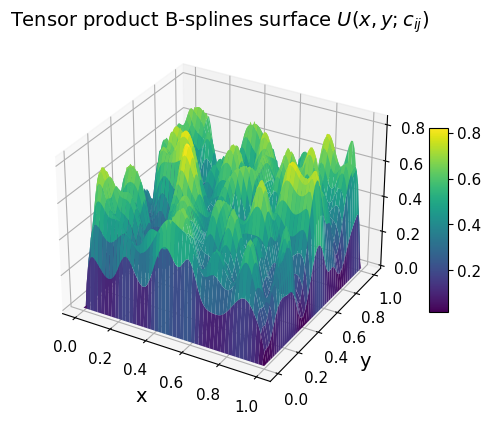

In [8]:
# Figure 4

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_y.forward(XY_torch).numpy().reshape(Xg.shape)
# fig, axs = plt.subplots(1, 3, figsize=(15, 4))


# Plot surface
surf = ax.plot_surface(Xg, Yg, u_pred, cmap='viridis')  # Note the .T for correct orientation

# Add labels and colorbar
ax.set_title('Tensor product B-splines surface $U(x,y;c_{ij})$',fontsize=14)
ax.set_xlabel('x',fontsize=14)
ax.set_ylabel('y',fontsize=14)
ax.set_zlabel('u',fontsize=14)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10).ax.tick_params(labelsize=11) 
ax.tick_params(axis='both', labelsize=11)
# plt.savefig("surface_DC_poisson.pdf")
plt.show()